# Задание № 2. Комплексные числа. Геометрия комплексных чисел
Условия взяты из `Практические занятия Листок 2.pdf`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sympy import I, sqrt, pi, Rational
from scipy.special import gamma, rgamma
from IPython.display import display, Math
sp.init_printing()

def forms(z):
    '''Алгебраическая, тригонометрическая и показательная формы числа sympy.'''
    z = sp.nsimplify(sp.simplify(sp.expand_complex(z)))
    r, phi = sp.simplify(sp.Abs(z)), sp.simplify(sp.arg(z))
    display(Math(f'z={sp.latex(z)}={sp.latex(r)}\\left(\\cos({sp.latex(phi)})+i\\sin({sp.latex(phi)})\\right)={sp.latex(r)}e^{{i({sp.latex(phi)})}}'))
    return z

def roots_n(w, n):
    '''Все корни степени n из комплексного числа w.'''
    r, phi = abs(w), np.angle(w)
    return r**(1/n)*np.exp(1j*(phi+2*np.pi*np.arange(n))/n)

def plot_roots(ax, zs, title):
    t = np.linspace(0,2*np.pi,300); R = abs(zs[0])
    ax.plot(R*np.cos(t),R*np.sin(t),color='gray',lw=.8)
    ax.scatter(zs.real,zs.imag,color='r',zorder=3)
    for k,z in enumerate(zs): ax.annotate(f'$z_{{{k}}}$',(z.real,z.imag),textcoords='offset points',xytext=(5,5))
    ax.axhline(0,color='k',lw=.5); ax.axvline(0,color='k',lw=.5)
    ax.set_aspect('equal'); ax.grid(True,alpha=.4); ax.set_title(title)

**2.1.** Представить в алгебраической, тригонометрической и показательной формах:
$$a)\ \frac{(5+i)(7-6i)}{3+i};\quad b)\ \frac{(1+i)^5}{(1-i)^3};\quad c)\ \frac{(-1+i\sqrt3)^{15}}{(1-i)^{20}}+\frac{(-1-i\sqrt3)^{15}}{(1+i)^{20}}.$$

**a)** $(5+i)(7-6i)=41-23i$, и $\dfrac{41-23i}{3+i}=\dfrac{(41-23i)(3-i)}{10}=10-11i$.

**b)** $\dfrac{1+i}{1-i}=i$, поэтому выражение равно $i^3(1+i)^2=-i\cdot2i=2$.

**c)** $-1\pm i\sqrt3=2e^{\pm2\pi i/3}$, поэтому $(-1\pm i\sqrt3)^{15}=2^{15}e^{\pm10\pi i}=2^{15}$. Далее $(1\mp i)^{20}=2^{10}e^{\mp5\pi i}=-2^{10}$. Каждая дробь равна $-32$, сумма равна $-64$.

In [2]:
a = forms((5+I)*(7-6*I)/(3+I))
b = forms((1+I)**5/(1-I)**3)
c = forms((-1+I*sqrt(3))**15/(1-I)**20+(-1-I*sqrt(3))**15/(1+I)**20)
assert a==10-11*I and b==2 and c==-64

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**2.2.** Решить уравнение $z^8=1+i$ и изобразить решения.

$1+i=\sqrt2e^{i\pi/4}$, поэтому
$$z_k=2^{1/16}\exp\left(i\,\frac{\pi/4+2\pi k}{8}\right),\quad k=0,\dots,7.$$
Корни лежат в вершинах правильного восьмиугольника, вписанного в окружность радиуса $2^{1/16}$.

0 (1.03925+0.10236j)
1 (0.66248+0.80723j)
2 (-0.10236+1.03925j)
3 (-0.80723+0.66248j)
4 (-1.03925-0.10236j)
5 (-0.66248-0.80723j)
6 (0.10236-1.03925j)
7 (0.80723-0.66248j)


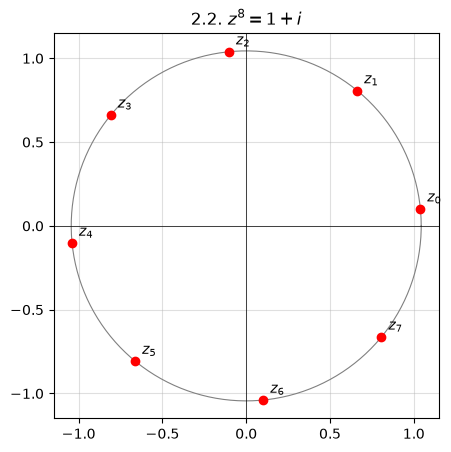

In [3]:
zs = roots_n(1+1j,8)
assert np.allclose(zs**8,1+1j)
for k,z in enumerate(zs): print(k,np.round(z,5))
fig,ax = plt.subplots(figsize=(5,5)); plot_roots(ax,zs,'2.2. $z^8=1+i$')
fig.savefig('fig/Sol_2_2.png',dpi=120,bbox_inches='tight'); plt.show()

**2.3.** Вычислить над $\mathbb C$ и изобразить:
$$a)\ \sqrt[8]{1};\quad b)\ \sqrt[4]{-\frac{18}{1+i\sqrt3}};\quad c)\ \sqrt[3]{\frac{1-5i}{1+i}-5\,\frac{1+2i}{2-i}+11};\quad d)\ \sqrt[9]{1-i}.$$

**a)** $z_k=e^{i\pi k/4}$, $k=0,\dots,7$.

**b)** $-\dfrac{18}{1+i\sqrt3}=-\dfrac{18(1-i\sqrt3)}{4}=9e^{2\pi i/3}$, поэтому $z_k=\sqrt3\,e^{i(\pi/6+\pi k/2)}$, $k=0,\dots,3$.

**c)** $\dfrac{1-5i}{1+i}=-2-3i$, $\dfrac{1+2i}{2-i}=i$. Подкоренное выражение равно $-2-3i-5i+11=9-8i$. Его модуль равен $\sqrt{145}$, поэтому $z_k=145^{1/6}\exp\left(i\,\dfrac{-\operatorname{arctg}(8/9)+2\pi k}{3}\right)$, $k=0,1,2$.

**d)** $1-i=\sqrt2e^{-i\pi/4}$, поэтому $z_k=2^{1/18}\exp\left(i\,\dfrac{-\pi/4+2\pi k}{9}\right)$, $k=0,\dots,8$.

a) $\sqrt[8]{1}$ [ 1.    +0.j      0.7071+0.7071j  0.    +1.j     -0.7071+0.7071j
 -1.    +0.j     -0.7071-0.7071j -0.    -1.j      0.7071-0.7071j]
b) $\sqrt[4]{9e^{2\pi i/3}}$ [ 1.5  +0.866j -0.866+1.5j   -1.5  -0.866j  0.866-1.5j  ]
c) $\sqrt[3]{9-8i}$ [ 2.2252-0.5498j -0.6365+2.2019j -1.5887-1.6522j]
d) $\sqrt[9]{1-i}$ [ 1.0353-0.0906j  0.8513+0.5961j  0.269 +1.0038j -0.4392+0.9419j
 -0.9419+0.4392j -1.0038-0.269j  -0.5961-0.8513j  0.0906-1.0353j
  0.7349-0.7349j]


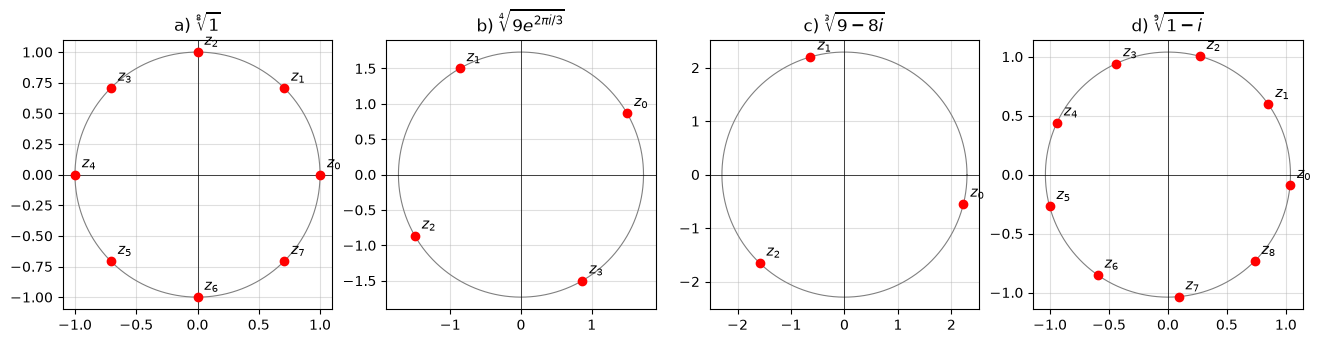

In [4]:
w_c = (1-5j)/(1+1j)-5*(1+2j)/(2-1j)+11
assert np.isclose(w_c,9-8j)
assert np.isclose(-18/(1+1j*np.sqrt(3)),9*np.exp(2j*np.pi/3))
items = [('a) $\\sqrt[8]{1}$',1,8),('b) $\\sqrt[4]{9e^{2\\pi i/3}}$',-18/(1+1j*np.sqrt(3)),4),
         ('c) $\\sqrt[3]{9-8i}$',w_c,3),('d) $\\sqrt[9]{1-i}$',1-1j,9)]
fig,axs = plt.subplots(1,4,figsize=(16,4))
for ax,(title,w,k) in zip(axs,items):
    zs = roots_n(w,k); assert np.allclose(zs**k,w)
    print(title,np.round(zs,4)); plot_roots(ax,zs,title)
fig.savefig('fig/Sol_2_3.png',dpi=120,bbox_inches='tight'); plt.show()

**2.4.** Изобразить множества.

**a)** $|z-i|+|z+i|<4$. Это внутренность эллипса с фокусами $\pm i$ и большой осью $2a=4$: $a=2$, $c=1$, $b^2=3$, то есть $\dfrac{x^2}{3}+\dfrac{y^2}{4}<1$.

**b)** $\operatorname{Re}(z(1-i))=x+y<\sqrt2$. Это полуплоскость.

**c)** $|z+1|=|z+i|=|z-i|$. Из равенства $|z+i|=|z-i|$ следует $y=0$, из $|z+1|=|z+i|$ следует $y=x$. Множество состоит из одной точки $z=0$ — центра окружности через точки $-1,\pm i$.

**d)** $0<\arg\dfrac{i-z}{z+i}<\dfrac\pi2$. Домножая на сопряжённое к знаменателю, получаем
$$\frac{i-z}{z+i}=\frac{(1-x^2-y^2)+2ix}{|z+i|^2}.$$
Условие означает, что действительная и мнимая части положительны: $x^2+y^2<1$, $x>0$. Это открытый правый полукруг.

**e)** $-\dfrac{2\pi}3\leqslant\arg\dfrac{2-iz}{z+3i}\leqslant-\dfrac{5\pi}6$. *В листке границы записаны в обратном порядке: $-2\pi/3>-5\pi/6$, поэтому буквально множество пусто. Ниже построен вариант с исправленным порядком, $-\dfrac{5\pi}6\leqslant\arg\leqslant-\dfrac{2\pi}3$.* Так как $2-iz=-i(z+2i)$, имеем $\arg\dfrac{2-iz}{z+3i}=\arg\dfrac{z+2i}{z+3i}-\dfrac\pi2$ (по модулю $2\pi$), то есть $\arg\dfrac{z+2i}{z+3i}\in\left[-\dfrac\pi3,-\dfrac\pi6\right]$. Границы множества — дуги окружностей через точки $-2i$ и $-3i$, из которых отрезок между этими точками виден под постоянным углом.

**f)** $-\dfrac{2\pi}3\leqslant\arg\dfrac{3-z}{z+i}\leqslant-\dfrac\pi3$. Границы — дуги окружностей через точки $3$ и $-i$, из которых отрезок $[-i,3]$ виден под постоянным углом.

Множества d, e, f построены прямой проверкой условия в узлах сетки. Главное значение аргумента берётся из $(-\pi,\pi]$.

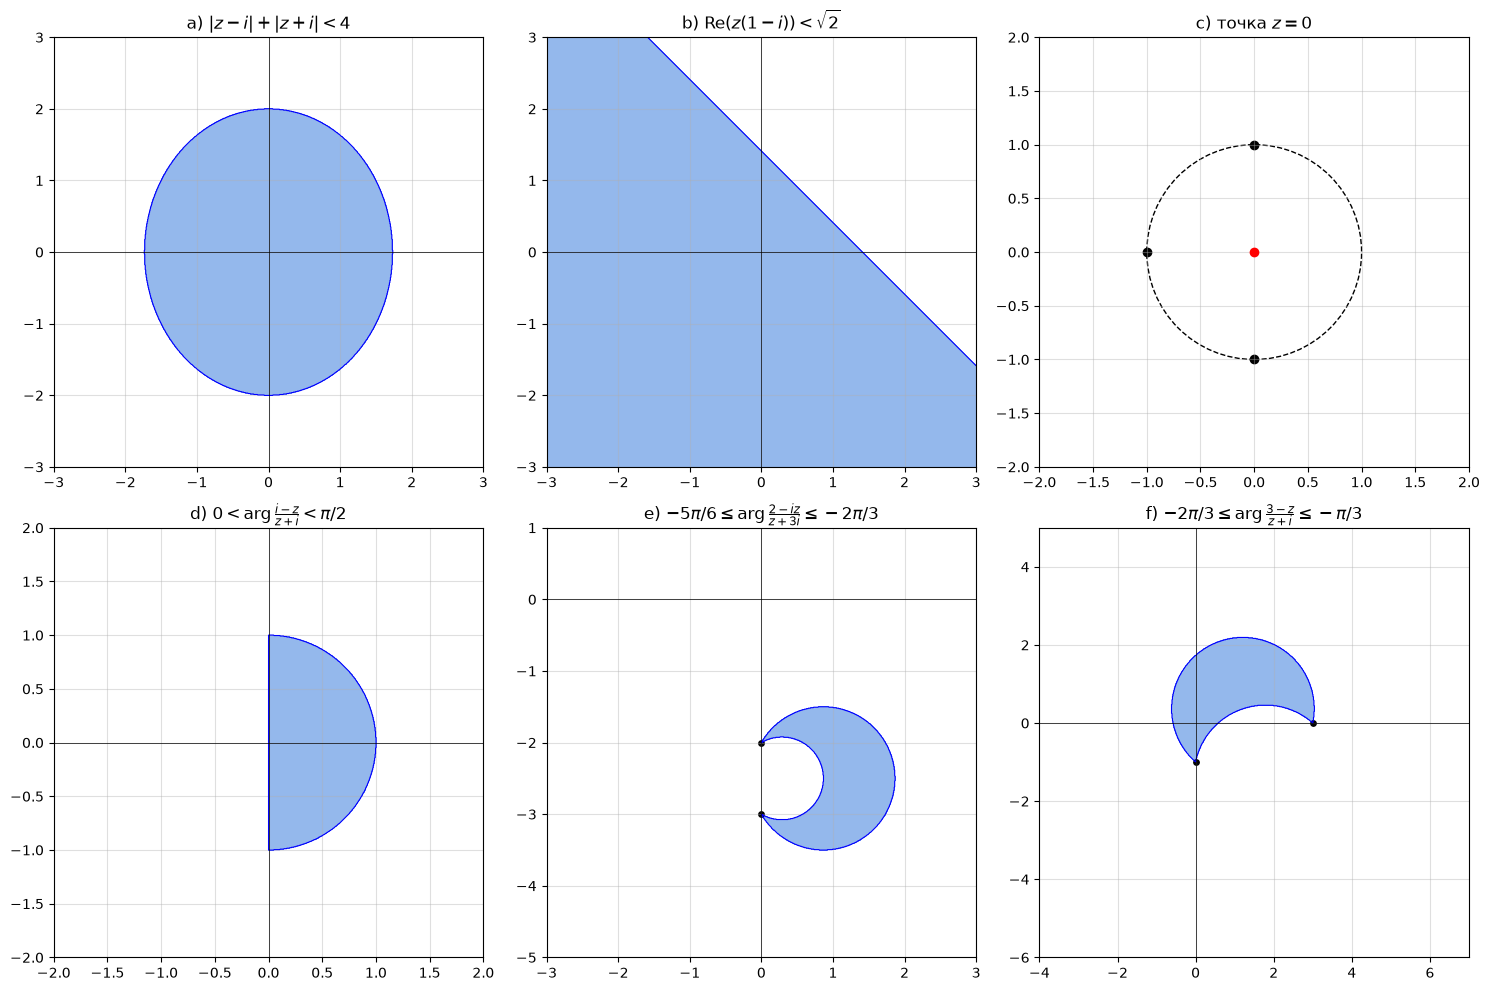

In [5]:
def region(ax,mask_fn,lim,title,extra=None):
    x,y = np.meshgrid(np.linspace(*lim[:2],900),np.linspace(*lim[2:],900))
    z = x+1j*y
    with np.errstate(all='ignore'):
        m = mask_fn(z)
    ax.contourf(x,y,m.astype(float),levels=[.5,1.5],colors=['#7aa6e8'],alpha=.8)
    ax.contour(x,y,m.astype(float),levels=[.5],colors='b',linewidths=.8)
    ax.axhline(0,color='k',lw=.5); ax.axvline(0,color='k',lw=.5)
    ax.set_aspect('equal'); ax.grid(True,alpha=.4); ax.set_title(title)
    if extra: extra(ax)

ANG = np.angle
fig,axs = plt.subplots(2,3,figsize=(15,10))
region(axs[0,0],lambda z:abs(z-1j)+abs(z+1j)<4,(-3,3,-3,3),'a) $|z-i|+|z+i|<4$')
region(axs[0,1],lambda z:(z*(1-1j)).real<np.sqrt(2),(-3,3,-3,3),'b) Re$(z(1-i))<\\sqrt{2}$')
axs[0,2].scatter([0],[0],color='r',zorder=3); axs[0,2].scatter([-1,0,0],[0,1,-1],color='k')
axs[0,2].add_patch(plt.Circle((0,0),1,fill=False,ls='--')); axs[0,2].set_xlim(-2,2); axs[0,2].set_ylim(-2,2)
axs[0,2].set_aspect('equal'); axs[0,2].grid(True,alpha=.4); axs[0,2].set_title('c) точка $z=0$')
region(axs[1,0],lambda z:(ANG((1j-z)/(z+1j))>0)&(ANG((1j-z)/(z+1j))<np.pi/2),(-2,2,-2,2),'d) $0<\\arg\\frac{i-z}{z+i}<\\pi/2$')
region(axs[1,1],lambda z:(ANG((2-1j*z)/(z+3j))>=-5*np.pi/6)&(ANG((2-1j*z)/(z+3j))<=-2*np.pi/3),(-3,3,-5,1),'e) $-5\\pi/6\\leq\\arg\\frac{2-iz}{z+3i}\\leq-2\\pi/3$',
       lambda a:a.scatter([0,0],[-2,-3],color='k',s=15))
region(axs[1,2],lambda z:(ANG((3-z)/(z+1j))>=-2*np.pi/3)&(ANG((3-z)/(z+1j))<=-np.pi/3),(-4,7,-6,5),'f) $-2\\pi/3\\leq\\arg\\frac{3-z}{z+i}\\leq-\\pi/3$',
       lambda a:a.scatter([3,0],[0,-1],color='k',s=15))
fig.tight_layout(); fig.savefig('fig/Sol_2_4.png',dpi=120,bbox_inches='tight'); plt.show()

In [6]:
# Проверка формулы из пункта d в случайных точках
rng = np.random.default_rng(0)
z = rng.normal(size=5)+1j*rng.normal(size=5)
lhs = (1j-z)/(z+1j); rhs = ((1-abs(z)**2)+2j*z.real)/abs(z+1j)**2
assert np.allclose(lhs,rhs); print('формула пункта d верна')

формула пункта d верна


**2.5.\*** Пусть $A,C\in\mathbb R$, $B\in\mathbb C$, $A>0$, $AC<|B|^2$. Показать, что $A|z|^2+\overline Bz+B\overline z+C=0$ — уравнение окружности, найти центр и радиус.

Разделим на $A$ и выделим полный квадрат. Так как
$$\left|z+\frac BA\right|^2=\left(z+\frac BA\right)\left(\overline z+\frac{\overline B}{A}\right)=|z|^2+\frac{\overline Bz+B\overline z}{A}+\frac{|B|^2}{A^2},$$
уравнение равносильно
$$\left|z+\frac BA\right|^2=\frac{|B|^2-AC}{A^2}.$$
Правая часть положительна по условию. Значит, это окружность с **центром $z_0=-B/A$ и радиусом $R=\dfrac{\sqrt{|B|^2-AC}}{A}$**.

**2.6.** Найти все 11 корней $p(x)=x^{11}+x^{10}+x^8-2x^7-x^5+x^4+2x^2+2x+2$; указать сумму модулей и наибольшую действительную часть.

-1.776769  |p| = 1.1e-38
(1.0806017 - 0.32389312j)  |p| = 9.1e-41
(1.0806017 + 0.32389312j)  |p| = 9.1e-41
(-0.70743446 + 0.46437473j)  |p| = 6.0e-41
(-0.70743446 - 0.46437473j)  |p| = 6.0e-41
(-0.45003711 + 0.80392314j)  |p| = 5.3e-41
(-0.45003711 - 0.80392314j)  |p| = 5.3e-41
(0.47775452 + 0.90107523j)  |p| = 5.5e-41
(0.47775452 - 0.90107523j)  |p| = 5.5e-41
(-0.012500181 + 1.1826991j)  |p| = 3.2e-40
(-0.012500181 - 1.1826991j)  |p| = 3.2e-40
сумма модулей = 11.97338447
max Re = 1.080601737


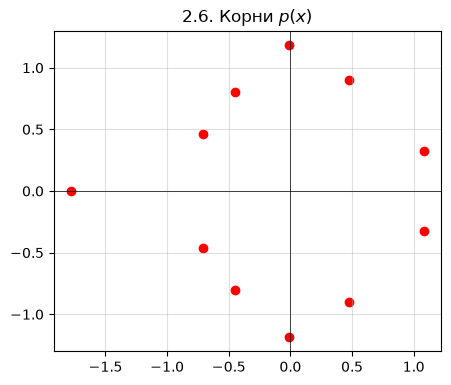

In [7]:
import mpmath as mp
mp.mp.dps = 40
coef = [1,1,0,1,-2,0,-1,1,0,2,2,2]   # коэффициенты при x^11,...,x^0
x = sp.symbols('x')
assert sp.Poly(coef,x).as_expr()==x**11+x**10+x**8-2*x**7-x**5+x**4+2*x**2+2*x+2
rts = mp.polyroots(coef,maxsteps=500,extraprec=200)
for r in rts: print(mp.nstr(r,8), ' |p| =',mp.nstr(abs(mp.polyval(coef,r)),2))
print('сумма модулей =',mp.nstr(sum(abs(r) for r in rts),10))
print('max Re =',mp.nstr(max(mp.re(r) for r in rts),10))
zz = np.array([complex(r) for r in rts])
fig,ax = plt.subplots(figsize=(5,5)); ax.scatter(zz.real,zz.imag,color='r'); ax.axhline(0,color='k',lw=.5); ax.axvline(0,color='k',lw=.5)
ax.set_aspect('equal'); ax.grid(True,alpha=.4); ax.set_title('2.6. Корни $p(x)$')
fig.savefig('fig/Sol_2_6.png',dpi=120,bbox_inches='tight'); plt.show()

**Ответ:** $\sum|z_k|\approx11{,}97338$; наибольшая действительная часть $\approx1{,}08060$.

**2.7.** $C_z^w=\dfrac{\Gamma(z+1)}{\Gamma(w+1)\Gamma(z-w+1)}$. Найти а) $C_{1+i}^{1-i}$; б) его аргумент; в) построить линии уровня $\operatorname{Arg}C_z^{1/z}=\text{const}$.

C = (4.36744914064015+4.8516297651578295j)
Arg = 0.8378693695500425 рад = 48.00637865850453 °


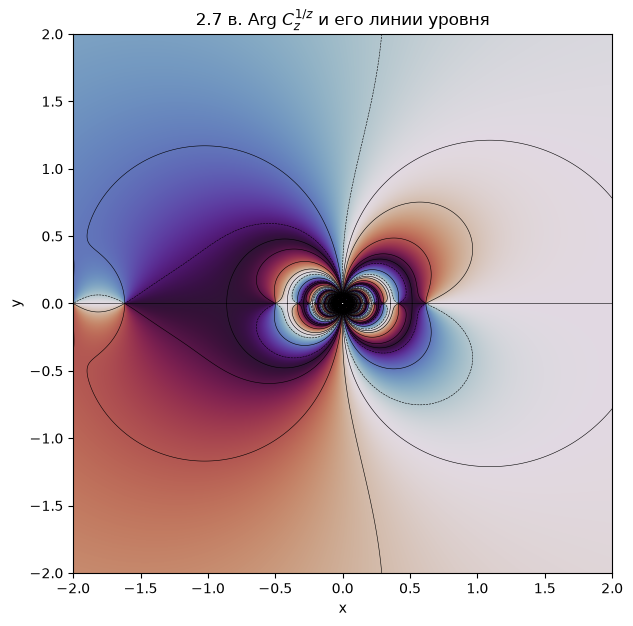

In [8]:
z,w = 1+1j,1-1j
C = gamma(z+1)/(gamma(w+1)*gamma(z-w+1))
print('C =',C); print('Arg =',np.angle(C),'рад =',np.degrees(np.angle(C)),'°')
assert np.isclose(C,4.36745+4.85163j,atol=1e-5) and np.isclose(np.angle(C),0.837869,atol=1e-6)

x,y = np.meshgrid(np.linspace(-2,2,1200),np.linspace(-2,2,1200))
Z = x+1j*y+1e-12
with np.errstate(all='ignore'):
    # rgamma = 1/Gamma не имеет полюсов, поэтому формула устойчива
    val = gamma(Z+1)*rgamma(1/Z+1)*rgamma(Z-1/Z+1)
arg = np.angle(val)
fig,ax = plt.subplots(figsize=(7,7))
ax.imshow(arg,extent=[-2,2,-2,2],origin='lower',cmap='twilight_shifted',vmin=-np.pi,vmax=np.pi)
ax.contour(x,y,np.sin(arg),levels=[-.5,0,.5],colors='k',linewidths=.4)
ax.contour(x,y,np.cos(arg),levels=[0],colors='k',linewidths=.4)
ax.set_title('2.7 в. Arg $C_z^{1/z}$ и его линии уровня'); ax.set_xlabel('x'); ax.set_ylabel('y')
fig.savefig('fig/Sol_2_7.png',dpi=130,bbox_inches='tight'); plt.show()

**2.8.** $\lambda$ — корень степени 14 из 1 с $\operatorname{Im}\lambda>0$ и наибольшей действительной частью, то есть $\lambda=e^{i\pi/7}$. Для $A=\begin{pmatrix}7&5\\6&2\end{pmatrix}$ найти $\det(A+\lambda I)$.

$\det(A+\lambda I)=(7+\lambda)(2+\lambda)-30=\lambda^2+9\lambda-16$.

In [9]:
lam = np.exp(1j*np.pi/7)
d = np.linalg.det(np.array([[7,5],[6,2]])+lam*np.eye(2))
assert np.isclose(d,lam**2+9*lam-16)
print(f'Re = {d.real:.6f}, Im = {d.imag:.6f}')

Re = -7.267790, Im = 4.686785


**Ответ:** $\operatorname{Re}\approx-7{,}26779$; $\operatorname{Im}\approx4{,}68679$.

**2.9.\*** Множества Жюлиа.

**в)** Для $f_c(z)=z^2+c$ при $c=-0{,}1+0{,}65i$ и $c=0{,}28+0{,}009i$ считаем число итераций до выхода за радиус ухода. Код векторизован, а не написан двойным циклом, как в листке: так он работает в сотни раз быстрее.

**г)** У отображения $f(z)=\dfrac{iz^5-1}{z^5-i}$ два притягивающих цикла: $i\leftrightarrow\infty$ и $0\leftrightarrow-i$. Поэтому окрашиваем точки по тому, куда приходит чётная итерация. Точки $0,i$ дают один цвет, точки $\infty,-i$ — другой, как на рисунке в листке. Граница бассейнов и есть множество Жюлиа. У $f(z)=\dfrac{z^2+i}{1-z^2}$ аналогичный цикл $-1\leftrightarrow\infty$, здесь используем время ухода.

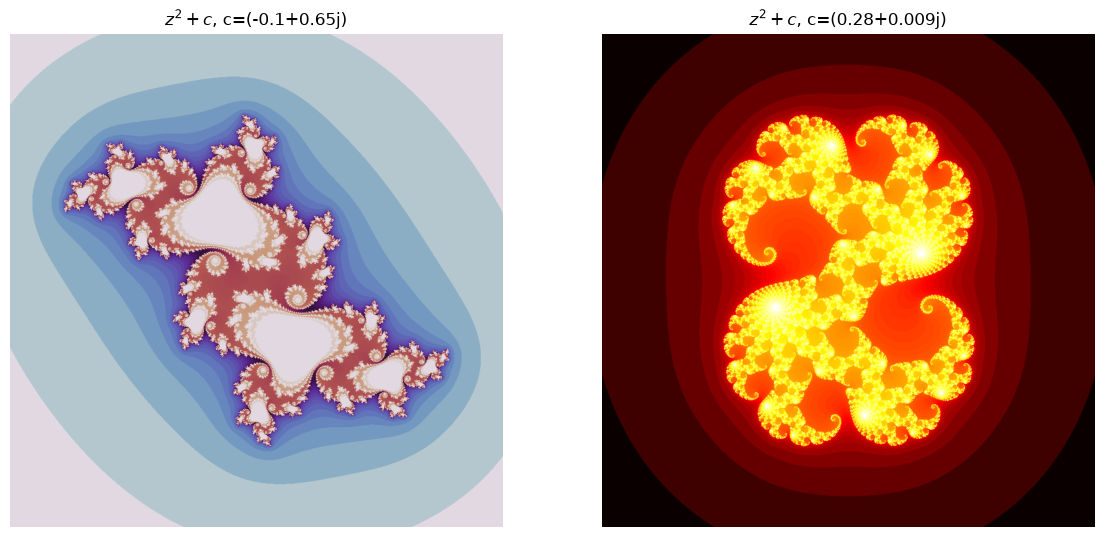

In [10]:
def grid(lim,N):
    x,y = np.meshgrid(np.linspace(-lim,lim,N),np.linspace(-lim,lim,N))
    return x+1j*y

def escape_time(f,z,nmax=300,R=10.):
    '''Число итераций до |z|>R; зависшие точки получают значение nmax.'''
    z = z.copy(); cnt = np.full(z.shape,nmax,dtype=int)
    alive = np.ones(z.shape,bool)
    with np.errstate(all='ignore'):
        for k in range(nmax):
            z[alive] = f(z[alive])
            out = alive&~(np.abs(z)<=R)
            cnt[out] = k; alive &= ~out
    return cnt

fig,axs = plt.subplots(1,2,figsize=(14,7))
for ax,c,cm in zip(axs,[-0.1+0.65j,0.28+0.009j],['twilight','hot']):
    t = escape_time(lambda z,c=c:z*z+c,grid(1.6,900))
    ax.imshow(np.log1p(t),extent=[-1.6,1.6,-1.6,1.6],origin='lower',cmap=cm); ax.set_title(f'$z^2+c$, c={c}'); ax.axis('off')
fig.savefig('fig/Sol_2_9v.png',dpi=110,bbox_inches='tight'); plt.show()

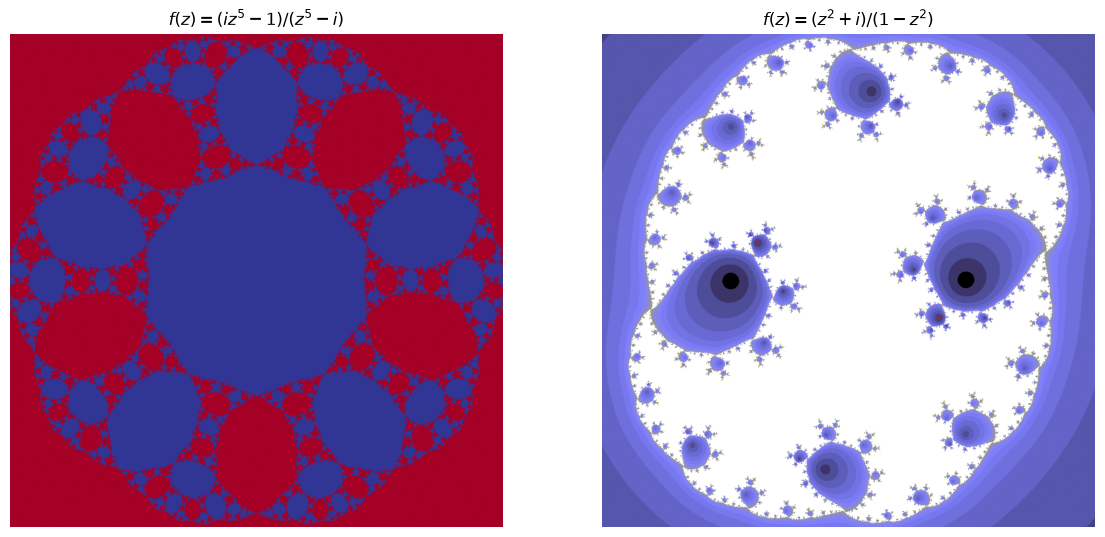

In [11]:
def basin_rational(z,steps=60):
    '''Для f=(i z^5-1)/(z^5-i): 1 - чётные итерации приходят к 0 или i, 0 - к бесконечности или -i.'''
    z = z.copy()
    with np.errstate(all='ignore'):
        for _ in range(steps):
            z5 = z**5
            nz = (1j*z5-1)/(z5-1j)
            nz[~np.isfinite(z)] = 1j       # f(бесконечность)=i
            nz[np.isnan(nz)] = np.inf
            z = nz
    return ((np.abs(z-1j)<1e-3)|(np.abs(z)<1e-3)).astype(float)

fig,axs = plt.subplots(1,2,figsize=(14,7))
f = lambda z:(1j*z**5-1)/(z**5-1j)
assert np.isclose(f(0),-1j) and np.isclose(f(-1j),0)   # проверка цикла
b = basin_rational(grid(1.5,900).astype(complex))
axs[0].imshow(b,extent=[-1.5,1.5,-1.5,1.5],origin='lower',cmap='RdYlBu'); axs[0].set_title('$f(z)=(iz^5-1)/(z^5-i)$'); axs[0].axis('off')
t = escape_time(lambda z:(z*z+1j)/(1-z*z),grid(2.1,900),nmax=200)
axs[1].imshow(np.log1p(t),extent=[-2.1,2.1,-2.1,2.1],origin='lower',cmap='gist_stern'); axs[1].set_title('$f(z)=(z^2+i)/(1-z^2)$'); axs[1].axis('off')
fig.savefig('fig/Sol_2_9g.png',dpi=110,bbox_inches='tight'); plt.show()

**2.10.\*** Сфера Римана. Сфера диаметра $1$ касается плоскости в нуле, $N=(0,0,1)$ — северный полюс. Стереографическая проекция точки $z=x+iy$:
$$(X,Y,Z)=\left(\frac{x}{1+|z|^2},\ \frac{y}{1+|z|^2},\ \frac{|z|^2}{1+|z|^2}\right).$$
Образ прямой — окружность через $N$; образ окружности — окружность. Парабола и ветви гиперболы уходят в бесконечность, поэтому их образы проходят через $N$.

**2.10.\* (второй пункт)** Логарифмическая спираль $r=ae^{b\varphi}$ при $\varphi\to\pm\infty$ наматывается и на южный полюс ($z\to0$), и на северный ($z\to\infty$).

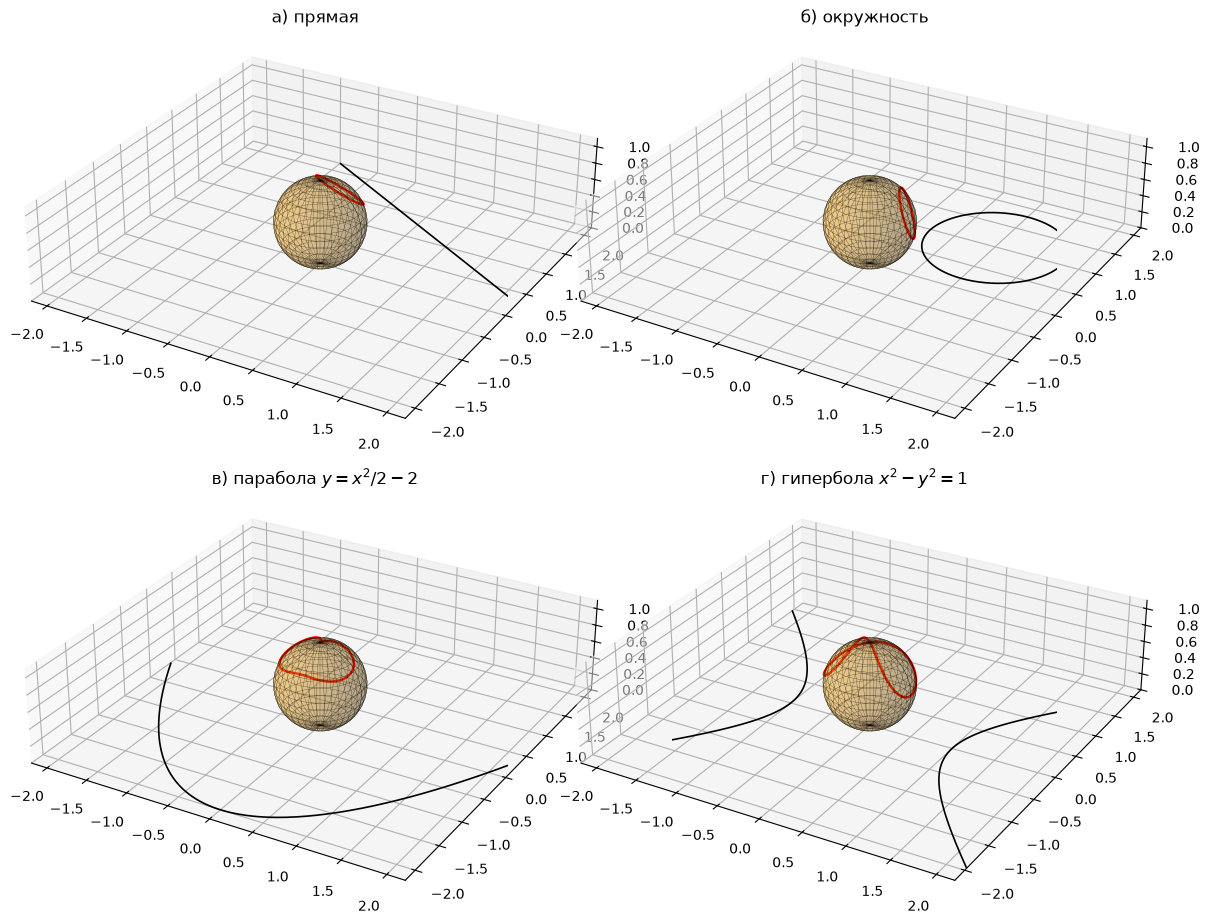

наименьшее сингулярное число (0 = точки в плоскости): 1.1307814114058947e-13


In [12]:
def stereo(z):
    d = 1+np.abs(z)**2
    return z.real/d,z.imag/d,np.abs(z)**2/d

def draw_sphere(ax):
    u,v = np.mgrid[0:2*np.pi:40j,0:np.pi:20j]
    ax.plot_surface(.5*np.cos(u)*np.sin(v),.5*np.sin(u)*np.sin(v),.5+.5*np.cos(v),color='orange',alpha=.25,linewidth=0)
    ax.plot_wireframe(.5*np.cos(u)*np.sin(v),.5*np.sin(u)*np.sin(v),.5+.5*np.cos(v),color='k',lw=.15)

def show(ax,curves,title,L=2.2):
    draw_sphere(ax)
    for z in curves:
        mask = (np.abs(z.real)<=L)&(np.abs(z.imag)<=L)
        pz = z.copy(); pz[~mask] = np.nan
        ax.plot(pz.real,pz.imag,0*pz.real,color='k',lw=1.2)
        ax.plot(*stereo(z),color='r',lw=1.8)
    ax.set_xlim(-L,L); ax.set_ylim(-L,L); ax.set_zlim(0,1.1); ax.set_box_aspect((2*L,2*L,1.1),zoom=1.5)
    ax.set_title(title); ax.view_init(28,-60)

t = np.linspace(-60,60,6000)
circle = 1.0+1.0j+.8*np.exp(1j*np.linspace(0,2*np.pi,400))
fig = plt.figure(figsize=(13,11))
show(fig.add_subplot(221,projection='3d'),[(1+1j)+t*(1-.6j)],'a) прямая')
show(fig.add_subplot(222,projection='3d'),[circle],'б) окружность')
show(fig.add_subplot(223,projection='3d'),[t+1j*(t**2/2-2)],'в) парабола $y=x^2/2-2$')
s = np.linspace(-6,6,3000)
show(fig.add_subplot(224,projection='3d'),[np.cosh(s)+1j*np.sinh(s),-np.cosh(s)+1j*np.sinh(s)],'г) гипербола $x^2-y^2=1$')
fig.savefig('fig/Sol_2_10.png',dpi=110,bbox_inches='tight'); plt.show()

# Проверка: образ прямой лежит на сфере и в одной плоскости (то есть это окружность)
X,Y,Z_ = stereo((1+1j)+t*(1-.6j))
assert np.allclose(X**2+Y**2+(Z_-.5)**2,.25)
pts = np.c_[X,Y,Z_]; pts = pts-pts.mean(0)
print('наименьшее сингулярное число (0 = точки в плоскости):',np.linalg.svd(pts,compute_uv=False)[-1])

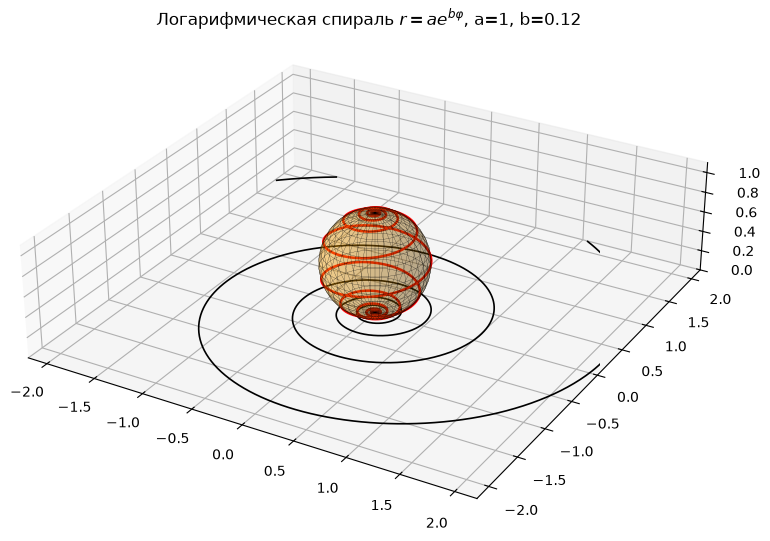

In [13]:
a,b = 1.,.12
phi = np.linspace(-40,40,8000)
z = a*np.exp(b*phi)*np.exp(1j*phi)
fig = plt.figure(figsize=(7,6)); ax = fig.add_subplot(projection='3d')
show(ax,[z],'Логарифмическая спираль $r=ae^{b\\varphi}$, a=1, b=0.12')
fig.savefig('fig/Sol_2_10_spiral.png',dpi=120,bbox_inches='tight'); plt.show()